In [2]:
import os
import numpy as np
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

DATA_DIR = os.path.join("..", "data", "processed")

X_train = np.load(os.path.join(DATA_DIR, "X_train.npy"))
y_train = np.load(os.path.join(DATA_DIR, "y_train.npy"))
X_val = np.load(os.path.join(DATA_DIR, "X_validation.npy"))
y_val = np.load(os.path.join(DATA_DIR, "y_validation.npy"))
X_test = np.load(os.path.join(DATA_DIR, "X_test.npy"))
y_test = np.load(os.path.join(DATA_DIR, "y_test.npy"))

# Ajouter la dimension du canal (le CNN attend (hauteur, largeur, canaux))
X_train = X_train[..., np.newaxis]
X_val = X_val[..., np.newaxis]
X_test = X_test[..., np.newaxis]

print("X_train:", X_train.shape, "y_train:", y_train.shape)
print("X_val:  ", X_val.shape, "y_val:  ", y_val.shape)
print("X_test: ", X_test.shape, "y_test: ", y_test.shape)

print("\nRépartition des classes (train):", np.bincount(y_train))
print("Répartition des classes (val):  ", np.bincount(y_val))

X_train: (4434, 224, 224, 1) y_train: (4434,)
X_val:   (782, 224, 224, 1) y_val:   (782,)
X_test:  (624, 224, 224, 1) y_test:  (624,)

Répartition des classes (train): [1140 3294]
Répartition des classes (val):   [201 581]


In [3]:
model = keras.Sequential([
    layers.Input(shape=(224, 224, 1)),

    layers.Conv2D(16, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Flatten(),
    layers.Dense(64, activation="relu"),
    layers.Dropout(0.5),
    layers.Dense(1, activation="sigmoid")  # sortie binaire : probabilité de PNEUMONIA
])

model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                      │ (None, 222, 222, 16)        │             160 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 111, 111, 16)        │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 109, 109, 32)        │           4,640 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 54, 54, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_2 (Conv2D)                    │ (None, 52, 52, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_2 (MaxPooling2D)       │ (None, 26, 26, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 43264)               │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 64)                  │       2,768,960 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 64)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 1)                   │              65 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 2,792,321 (10.65 MB)

 Trainable params: 2,792,321 (10.65 MB)

 Non-trainable params: 0 (0.00 B)

In [4]:
history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=10,
    batch_size=32
)

Epoch 1/10
139/139 ━━━━━━━━━━━━━━━━━━━━ 53s 352ms/step - accuracy: 0.8212 - loss: 0.4086 - val_accuracy: 0.8977 - val_loss: 0.2461
Epoch 2/10
139/139 ━━━━━━━━━━━━━━━━━━━━ 44s 316ms/step - accuracy: 0.9305 - loss: 0.2544 - val_accuracy: 0.9501 - val_loss: 0.2144
Epoch 3/10
139/139 ━━━━━━━━━━━━━━━━━━━━ 80s 303ms/step - accuracy: 0.9456 - loss: 0.2291 - val_accuracy: 0.9450 - val_loss: 0.2102
Epoch 4/10
139/139 ━━━━━━━━━━━━━━━━━━━━ 43s 313ms/step - accuracy: 0.9551 - loss: 0.2042 - val_accuracy: 0.9437 - val_loss: 0.1985
Epoch 5/10
139/139 ━━━━━━━━━━━━━━━━━━━━ 44s 316ms/step - accuracy: 0.9601 - loss: 0.1774 - val_accuracy: 0.9655 - val_loss: 0.1651
Epoch 7/10
139/139 ━━━━━━━━━━━━━━━━━━━━ 46s 332ms/step - accuracy: 0.9653 - loss: 0.1579 - val_accuracy: 0.9629 - val_loss: 0.1698
Epoch 8/10
139/139 ━━━━━━━━━━━━━━━━━━━━ 47s 335ms/step - accuracy: 0.9653 - loss: 0.1566 - val_accuracy: 0.9719 - val_loss: 0.1454
Epoch 9/10
139/139 ━━━━━━━━━━━━━━━━━━━━ 45s 321ms/step - accuracy: 0.9641 - loss: 0

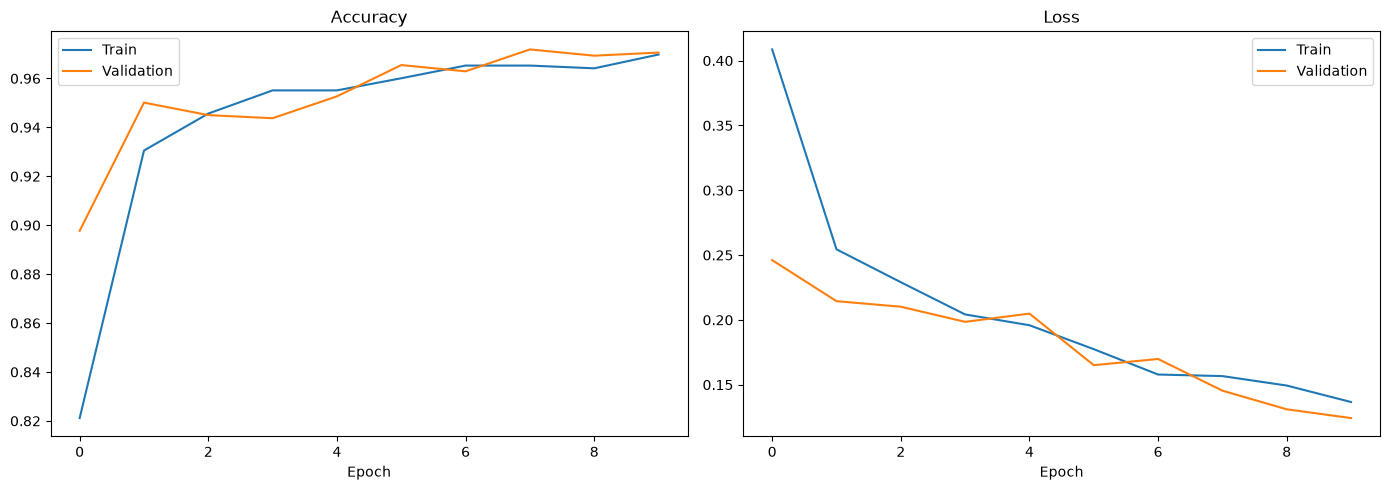

In [5]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(history.history["accuracy"], label="Train")
axes[0].plot(history.history["val_accuracy"], label="Validation")
axes[0].set_title("Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].legend()

axes[1].plot(history.history["loss"], label="Train")
axes[1].plot(history.history["val_loss"], label="Validation")
axes[1].set_title("Loss")
axes[1].set_xlabel("Epoch")
axes[1].legend()

plt.tight_layout()
plt.show()

In [6]:
os.makedirs(os.path.join("..", "models"), exist_ok=True)
model.save(os.path.join("..", "models", "model_v1_simple_cnn.keras"))
print("Modèle sauvegardé !")

Modèle sauvegardé !


In [7]:
model_path = os.path.join("..", "models", "model_v1_simple_cnn.keras")
print("Fichier existe:", os.path.exists(model_path))
print("Taille:", os.path.getsize(model_path) / (1024*1024), "MB")

Fichier existe: True
Taille: 32.001099586486816 MB


In [8]:
# Convertir les images grayscale (1 canal) en RGB (3 canaux) en dupliquant le canal
X_train_rgb = np.repeat(X_train, 3, axis=-1)
X_val_rgb = np.repeat(X_val, 3, axis=-1)
X_test_rgb = np.repeat(X_test, 3, axis=-1)

print("X_train_rgb shape:", X_train_rgb.shape)
print("X_val_rgb shape:", X_val_rgb.shape)
print("X_test_rgb shape:", X_test_rgb.shape)

X_train_rgb shape: (4434, 224, 224, 3)
X_val_rgb shape: (782, 224, 224, 3)
X_test_rgb shape: (624, 224, 224, 3)


In [9]:
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

# Préprocesser les images selon ce qu'attend MobileNetV2
# (Rappel : nos images sont déjà normalisées entre 0 et 1, MobileNet attend entre -1 et 1)
X_train_mnv2 = preprocess_input(X_train_rgb * 255.0)
X_val_mnv2 = preprocess_input(X_val_rgb * 255.0)
X_test_mnv2 = preprocess_input(X_test_rgb * 255.0)

# Charger MobileNetV2 pré-entraîné sur ImageNet, sans la couche de classification finale
base_model = MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,      # on retire la couche de classification d'origine (1000 classes ImageNet)
    weights="imagenet"      # on charge les poids pré-entraînés
)

# On "gèle" le modèle de base : ses poids ne seront pas modifiés pendant l'entraînement
base_model.trainable = False

# On construit notre propre modèle par-dessus
model_tl = keras.Sequential([
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dense(64, activation="relu"),
    layers.Dropout(0.5),
    layers.Dense(1, activation="sigmoid")
])

model_tl.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model_tl.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ mobilenetv2_1.00_224 (Functional)    │ (None, 7, 7, 1280)          │       2,257,984 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d             │ (None, 1280)                │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 64)                  │          81,984 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 64)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 1)                   │              65 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 2,340,033 (8.93 MB)

 Trainable params: 82,049 (320.50 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [16]:
history_tl = model_tl.fit(
    X_train_mnv2, y_train,
    validation_data=(X_val_mnv2, y_val),
    epochs=10,
    batch_size=32
)

Epoch 1/10
139/139 ━━━━━━━━━━━━━━━━━━━━ 114s 815ms/step - accuracy: 0.9899 - loss: 0.0277 - val_accuracy: 0.9731 - val_loss: 0.0641
Epoch 2/10
139/139 ━━━━━━━━━━━━━━━━━━━━ 108s 779ms/step - accuracy: 0.9896 - loss: 0.0270 - val_accuracy: 0.9757 - val_loss: 0.0605
Epoch 3/10
139/139 ━━━━━━━━━━━━━━━━━━━━ 116s 834ms/step - accuracy: 0.9905 - loss: 0.0232 - val_accuracy: 0.9770 - val_loss: 0.0552
Epoch 4/10
139/139 ━━━━━━━━━━━━━━━━━━━━ 117s 840ms/step - accuracy: 0.9905 - loss: 0.0244 - val_accuracy: 0.9731 - val_loss: 0.0590
Epoch 5/10
139/139 ━━━━━━━━━━━━━━━━━━━━ 119s 856ms/step - accuracy: 0.9948 - loss: 0.0169 - val_accuracy: 0.9744 - val_loss: 0.0643
Epoch 6/10
139/139 ━━━━━━━━━━━━━━━━━━━━ 125s 897ms/step - accuracy: 0.9928 - loss: 0.0228 - val_accuracy: 0.9731 - val_loss: 0.0668
Epoch 7/10
139/139 ━━━━━━━━━━━━━━━━━━━━ 120s 861ms/step - accuracy: 0.9917 - loss: 0.0204 - val_accuracy: 0.9719 - val_loss: 0.0973
Epoch 8/10
139/139 ━━━━━━━━━━━━━━━━━━━━ 119s 853ms/step - accuracy: 0.9917 -

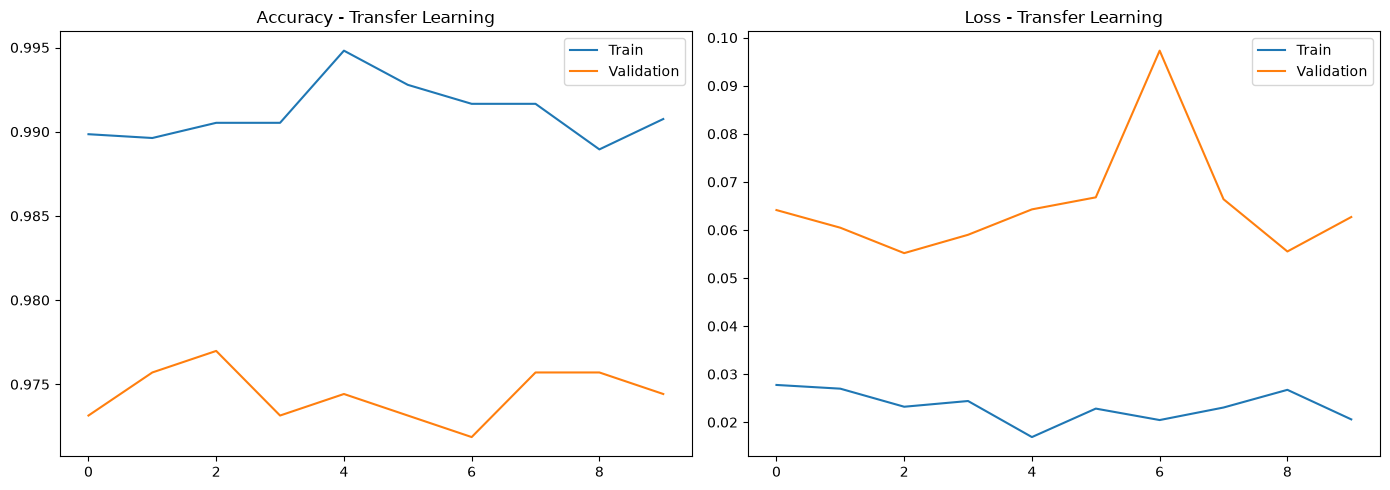

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(history_tl.history["accuracy"], label="Train")
axes[0].plot(history_tl.history["val_accuracy"], label="Validation")
axes[0].set_title("Accuracy - Transfer Learning")
axes[0].legend()

axes[1].plot(history_tl.history["loss"], label="Train")
axes[1].plot(history_tl.history["val_loss"], label="Validation")
axes[1].set_title("Loss - Transfer Learning")
axes[1].legend()

plt.tight_layout()
plt.show()

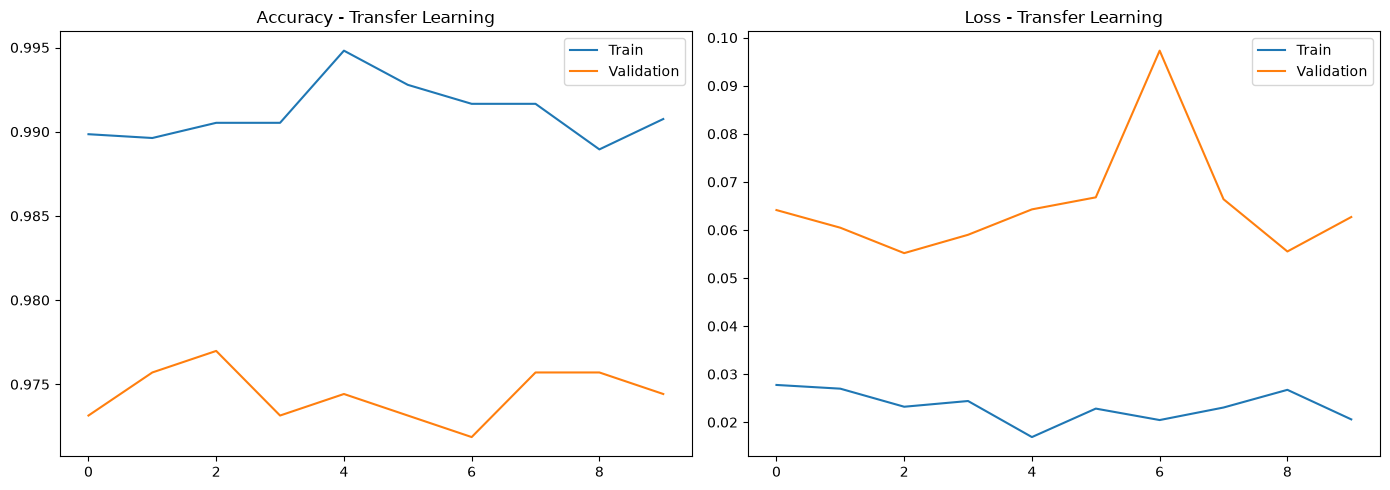

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(history_tl.history["accuracy"], label="Train")
axes[0].plot(history_tl.history["val_accuracy"], label="Validation")
axes[0].set_title("Accuracy - Transfer Learning")
axes[0].legend()

axes[1].plot(history_tl.history["loss"], label="Train")
axes[1].plot(history_tl.history["val_loss"], label="Validation")
axes[1].set_title("Loss - Transfer Learning")
axes[1].legend()

plt.tight_layout()
plt.show()

In [19]:
import matplotlib.pyplot as plt

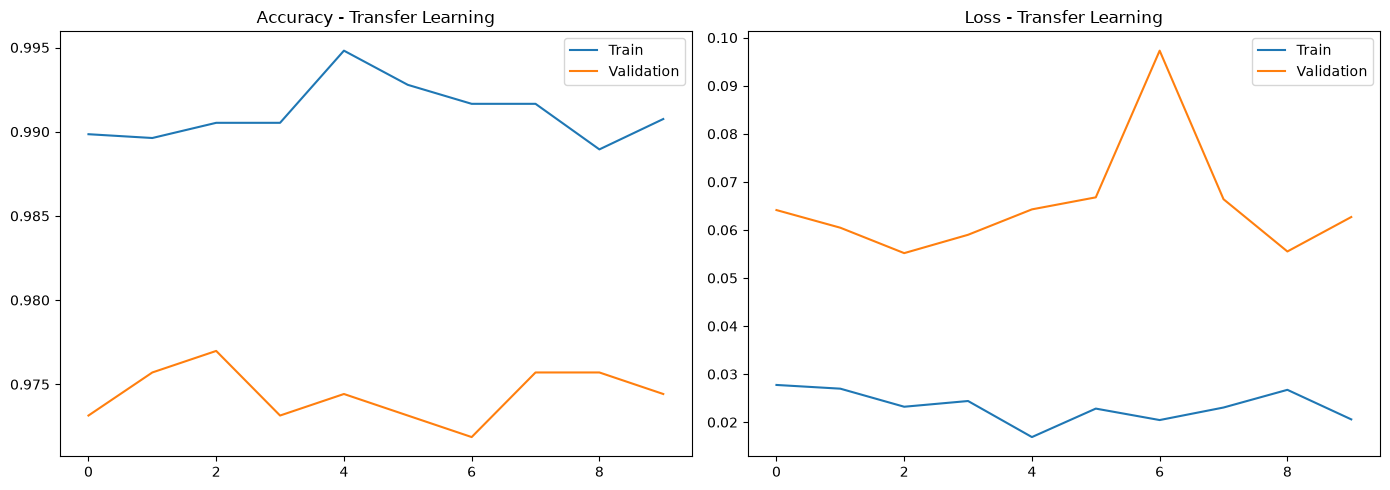

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(history_tl.history["accuracy"], label="Train")
axes[0].plot(history_tl.history["val_accuracy"], label="Validation")
axes[0].set_title("Accuracy - Transfer Learning")
axes[0].legend()

axes[1].plot(history_tl.history["loss"], label="Train")
axes[1].plot(history_tl.history["val_loss"], label="Validation")
axes[1].set_title("Loss - Transfer Learning")
axes[1].legend()

plt.tight_layout()
plt.show()

In [21]:
model_tl.save(os.path.join("..", "models", "model_v2_mobilenet_tl.keras"))
print("Modèle Transfer Learning sauvegardé !")

Modèle Transfer Learning sauvegardé !


In [22]:
from sklearn.utils.class_weight import compute_class_weight

# Calculer les poids de classes à partir du train
class_weights = compute_class_weight(
    class_weight="balanced",
    classes=np.unique(y_train),
    y=y_train
)
class_weight_dict = dict(enumerate(class_weights))
print("Poids calculés:", class_weight_dict)

# Reconstruire un modèle MobileNet identique (nouvelle instance, pas ré-entraîner l'ancien)
base_model_v3 = MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights="imagenet"
)
base_model_v3.trainable = False

model_tl_weighted = keras.Sequential([
    base_model_v3,
    layers.GlobalAveragePooling2D(),
    layers.Dense(64, activation="relu"),
    layers.Dropout(0.5),
    layers.Dense(1, activation="sigmoid")
])

model_tl_weighted.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

history_tl_weighted = model_tl_weighted.fit(
    X_train_mnv2, y_train,
    validation_data=(X_val_mnv2, y_val),
    epochs=10,
    batch_size=32,
    class_weight=class_weight_dict
)

Poids calculés: {0: np.float64(1.944736842105263), 1: np.float64(0.6730418943533698)}
Epoch 1/10
139/139 ━━━━━━━━━━━━━━━━━━━━ 174s 1s/step - accuracy: 0.9046 - loss: 0.2328 - val_accuracy: 0.9565 - val_loss: 0.1110
Epoch 2/10
139/139 ━━━━━━━━━━━━━━━━━━━━ 162s 1s/step - accuracy: 0.9605 - loss: 0.1095 - val_accuracy: 0.9668 - val_loss: 0.0827
Epoch 4/10
139/139 ━━━━━━━━━━━━━━━━━━━━ 163s 1s/step - accuracy: 0.9653 - loss: 0.0950 - val_accuracy: 0.9680 - val_loss: 0.0594
Epoch 5/10
139/139 ━━━━━━━━━━━━━━━━━━━━ 143s 1s/step - accuracy: 0.9687 - loss: 0.0876 - val_accuracy: 0.9706 - val_loss: 0.0659
Epoch 6/10
139/139 ━━━━━━━━━━━━━━━━━━━━ 137s 982ms/step - accuracy: 0.9709 - loss: 0.0796 - val_accuracy: 0.9693 - val_loss: 0.0630
Epoch 7/10
139/139 ━━━━━━━━━━━━━━━━━━━━ 150s 1s/step - accuracy: 0.9741 - loss: 0.0703 - val_accuracy: 0.9680 - val_loss: 0.0751
Epoch 8/10
139/139 ━━━━━━━━━━━━━━━━━━━━ 131s 938ms/step - accuracy: 0.9763 - loss: 0.0613 - val_accuracy: 0.9719 - val_loss: 0.0695
Epoch

In [23]:
model_tl_weighted.save(os.path.join("..", "models", "model_v3_mobilenet_weighted.keras"))
print("Modèle pondéré sauvegardé !")

Modèle pondéré sauvegardé !
